<a href="https://colab.research.google.com/github/goswamijenya-bit/Applied-Data-Science-1/blob/main/California_Housing_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Predicting California House Prices
### A data science project using Multiple Linear Regression, Decision Tree, Random Forest and K-Means Clustering

**Dataset:** California Housing (1990 US Census), Pace & Barry (1997), teaching version by Géron (2019)
**Data link:** https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv

**Research question:** *What factors affect house prices in California, and how accurately can we predict the median house value of a neighbourhood?*

**Steps in this notebook**
1. Setup – load the libraries
2. Load the data and understand it
3. Data cleaning (missing values, data types, capped values, outliers)
4. Feature engineering (create new useful columns)
5. Exploratory Data Analysis (EDA) – charts and correlations
6. Build the models – Multiple Linear Regression, Decision Tree, Random Forest
7. Evaluate and compare the models (R², MAE, RMSE)
8. K-Means clustering – group neighbourhoods into types
9. Summary of findings

👉 To run: **Runtime → Run all**. The notebook downloads the data by itself.

## Step 1 – Setup
We import the Python libraries we need:
* **pandas / numpy** – to work with tables and numbers
* **matplotlib / seaborn** – to draw charts
* **scikit-learn** – for the machine-learning models

In [ ]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, silhouette_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42                       # fixed seed so results are the same every run
os.makedirs("figures", exist_ok=True)   # charts are saved here
os.makedirs("results", exist_ok=True)   # result tables are saved here
RESULTS = {}                            # we store key numbers here for the report

# One consistent colour scheme for all charts
BLUE, ORANGE, GREEN, YELLOW, PINK, PURPLE = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"
MODEL_COLOURS = {"Multiple Linear Regression": BLUE, "Decision Tree": ORANGE, "Random Forest": GREEN}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e3df",
                     "axes.axisbelow": True, "axes.titleweight": "bold", "font.size": 10})

def save(fig, name):
    # Save a chart into the figures folder and show it
    fig.tight_layout()
    fig.savefig(f"figures/{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()

print("Libraries loaded ✔")

Libraries loaded ✔


## Step 2 – Load the data and understand it

Each row is one **neighbourhood** (a census "block group", about 600–3,000 people) in California in 1990.

| Column | Meaning |
|---|---|
| longitude, latitude | Location of the neighbourhood |
| housing_median_age | Median age of the houses (years) |
| total_rooms | Total number of rooms in the neighbourhood |
| total_bedrooms | Total number of bedrooms |
| population | Number of people living there |
| households | Number of households (families/homes) |
| median_income | Median household income (in **tens of thousands of US$**, e.g. 3.5 = $35,000) |
| ocean_proximity | How close to the ocean (text: <1H OCEAN, INLAND, NEAR OCEAN, NEAR BAY, ISLAND) |
| **median_house_value** | Median house price in US$ – **this is what we predict (target)** |

In [ ]:
URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

# Use the local file if it is already there, otherwise download it
if os.path.exists("housing.csv"):
    df = pd.read_csv("housing.csv")
else:
    df = pd.read_csv(URL)
    df.to_csv("housing.csv", index=False)   # keep a copy

print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()

Rows: 20640 | Columns: 10


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:
# Data types and number of non-empty values in each column
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


**What we see:**
* 20,640 neighbourhoods and 10 columns.
* `total_bedrooms` has fewer values than the other columns → **it has missing values**.
* `ocean_proximity` is **text**, so models cannot use it directly → we must convert it to numbers.

In [ ]:
# Basic statistics of every numeric column
df.describe().round(2)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.00,20640.00,20640.00,20640.00,20433.00,20640.00,20640.00,20640.00,20640.00
mean,-119.57,35.63,28.64,2635.76,537.87,1425.48,499.54,3.87,206855.82
std,2.00,2.14,12.59,2181.62,421.39,1132.46,382.33,1.90,115395.62
min,-124.35,32.54,1.00,2.00,1.00,3.00,1.00,0.50,14999.00
25%,-121.80,33.93,18.00,1447.75,296.00,787.00,280.00,2.56,119600.00
50%,-118.49,34.26,29.00,2127.00,435.00,1166.00,409.00,3.53,179700.00
75%,-118.01,37.71,37.00,3148.00,647.00,1725.00,605.00,4.74,264725.00
max,-114.31,41.95,52.00,39320.00,6445.00,35682.00,6082.00,15.00,500001.00


In [ ]:
RESULTS["n_rows"], RESULTS["n_cols"] = df.shape
RESULTS["ocean_counts"] = df["ocean_proximity"].value_counts().to_dict()
print(df["ocean_proximity"].value_counts())

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


## Step 3 – Data cleaning

We check four things:
1. **Missing values**
2. **Duplicate rows**
3. **Wrong data types** (text that should be numbers)
4. **Capped values / outliers**

### 3.1 Missing values

In [ ]:
missing = df.isnull().sum()
print(missing[missing > 0])
print(f"Percentage missing in total_bedrooms: {df['total_bedrooms'].isnull().mean():.1%}")
RESULTS["n_missing"] = int(df["total_bedrooms"].isnull().sum())

total_bedrooms    207
dtype: int64
Percentage missing in total_bedrooms: 1.0%


Only `total_bedrooms` has missing values (207 rows, about 1%).

**How do we fill them?** Bedrooms are closely related to rooms: a neighbourhood with more rooms has more bedrooms. So instead of using one average number for everyone, we estimate each missing value as:

> missing bedrooms = total_rooms × (median ratio of bedrooms to rooms)

This gives a more realistic estimate than a simple average.

In [ ]:
# Correlation between rooms and bedrooms (shows why our method makes sense)
print("Correlation rooms vs bedrooms:", round(df["total_rooms"].corr(df["total_bedrooms"]), 3))

bedroom_ratio = (df["total_bedrooms"] / df["total_rooms"]).median()
print("Median bedrooms per room:", round(bedroom_ratio, 3))

df["total_bedrooms"] = df["total_bedrooms"].fillna(df["total_rooms"] * bedroom_ratio).round()
print("Missing values left:", df.isnull().sum().sum())
RESULTS["bedroom_ratio"] = round(float(bedroom_ratio), 3)
RESULTS["rooms_bedrooms_corr"] = round(float(df['total_rooms'].corr(df['total_bedrooms'])), 3)

Correlation rooms vs bedrooms: 0.93
Median bedrooms per room: 0.203
Missing values left: 0


### 3.2 Duplicate rows

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


### 3.3 Data types
`ocean_proximity` is text. Models only understand numbers, so we use **one-hot encoding**: one new 0/1 column for each category (for example `ocean_INLAND` = 1 if the neighbourhood is inland). We also convert count columns to whole numbers.

In [ ]:
for col in ["housing_median_age", "total_rooms", "total_bedrooms", "population", "households"]:
    df[col] = df[col].astype(int)        # these are counts, so whole numbers

df["ocean_proximity"] = df["ocean_proximity"].astype("category")
print(df.dtypes)

longitude              float64
latitude               float64
housing_median_age       int64
total_rooms              int64
total_bedrooms           int64
population               int64
households               int64
median_income          float64
median_house_value     float64
ocean_proximity       category
dtype: object


### 3.4 Capped values (an important data problem)
When the census data was prepared, very high values were **capped**: every house worth more than $500,000 was recorded as exactly **$500,001**. The real price of these homes is unknown. House age is also capped at 52 years.

Neighbourhoods with capped price: 965 (4.7%)
Neighbourhoods with capped age (52): 1273


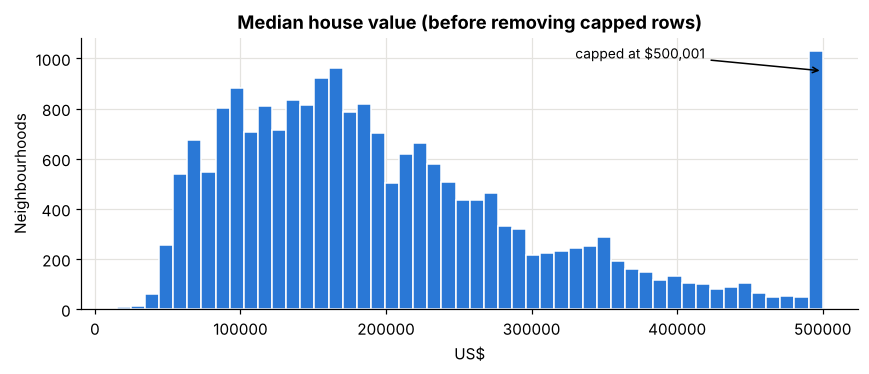

In [ ]:
capped = df["median_house_value"] >= 500001
print(f"Neighbourhoods with capped price: {capped.sum()} ({capped.mean():.1%})")
print(f"Neighbourhoods with capped age (52): {(df['housing_median_age'] == 52).sum()}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df["median_house_value"], bins=50, color=BLUE, edgecolor="white")
ax.annotate("capped at $500,001", xy=(500001, 950), xytext=(330000, 1000),
            arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.set(title="Median house value (before removing capped rows)", xlabel="US$", ylabel="Neighbourhoods")
save(fig, "fig01_price_capped")
RESULTS["n_capped"] = int(capped.sum())

**Decision:** we **remove the 965 capped rows** (4.7%). Their true price is unknown, so keeping them would teach the model wrong values. The capped house age (52) is kept, because "52 or older" is still a correct description.

In [ ]:
df = df[df["median_house_value"] < 500001].reset_index(drop=True)
print("Rows after removing capped prices:", len(df))
RESULTS["n_after_cap"] = len(df)

Rows after removing capped prices: 19675


## Step 4 – Feature engineering
Raw totals such as `total_rooms` are not very useful on their own: a big neighbourhood naturally has more rooms. It is more meaningful to look at values **per household**. We create:

| New feature | Formula | Meaning |
|---|---|---|
| rooms_per_household | total_rooms ÷ households | Average house size |
| bedrooms_per_room | total_bedrooms ÷ total_rooms | Share of rooms that are bedrooms (lower = more living space) |
| people_per_household | population ÷ households | How crowded homes are |
| income_level | groups of median_income | Low / Middle / High / Very high income (for charts) |
| is_inland | 1 if INLAND, else 0 | Simple yes/no flag for inland areas |

In [ ]:
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["people_per_household"] = df["population"] / df["households"]
df["is_inland"] = (df["ocean_proximity"] == "INLAND").astype(int)
df["income_level"] = pd.cut(df["median_income"], bins=[0, 2.5, 4.5, 6, np.inf],
                            labels=["Low (<$25k)", "Middle ($25–45k)", "High ($45–60k)", "Very high (>$60k)"])

new_cols = ["rooms_per_household", "bedrooms_per_room", "people_per_household"]
df[new_cols].describe().round(2)

,rooms_per_household,bedrooms_per_room,people_per_household
count,19675.00,19675.00,19675.00
mean,5.36,0.21,3.10
std,2.29,0.06,10.63
min,0.85,0.10,0.69
25%,4.41,0.18,2.45
50%,5.18,0.20,2.84
75%,5.97,0.24,3.30
max,132.53,1.00,1243.33


The new ratio columns have a few **extreme outliers** (for example 1,243 people per household, which is likely a prison or student dormitory). We **cap** them at the 1st and 99th percentiles so a few strange values do not distort the models.

In [ ]:
for col in new_cols:
    low, high = df[col].quantile([0.01, 0.99])
    df[col] = df[col].clip(low, high)
df[new_cols].describe().round(2)

,rooms_per_household,bedrooms_per_room,people_per_household
count,19675.00,19675.00,19675.00
mean,5.27,0.21,2.94
std,1.27,0.05,0.73
min,2.58,0.13,1.56
25%,4.41,0.18,2.45
50%,5.18,0.20,2.84
75%,5.97,0.24,3.30
max,10.35,0.41,5.41


## Step 5 – Exploratory Data Analysis (EDA)
### 5.1 How are house prices distributed?

count     19675.0
mean     192478.0
std       97712.0
min       14999.0
25%      116600.0
50%      173800.0
75%      248200.0
max      500000.0
Name: median_house_value, dtype: float64


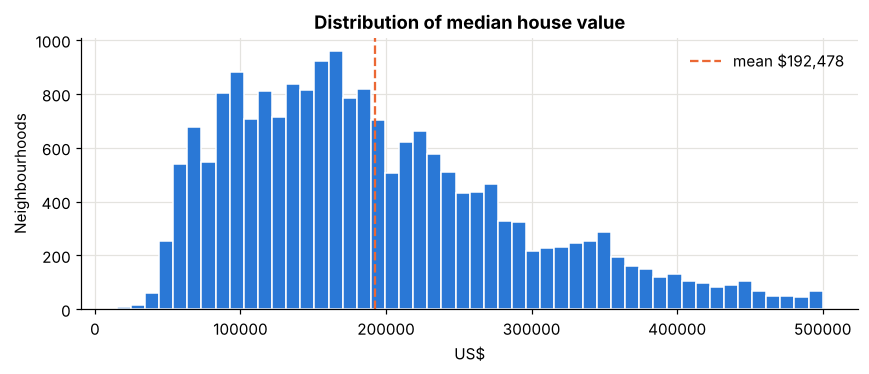

In [ ]:
print(df["median_house_value"].describe().round(0))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df["median_house_value"], bins=50, color=BLUE, edgecolor="white")
ax.axvline(df["median_house_value"].mean(), color=ORANGE, linestyle="--", label=f"mean ${df['median_house_value'].mean():,.0f}")
ax.set(title="Distribution of median house value", xlabel="US$", ylabel="Neighbourhoods")
ax.legend(frameon=False)
save(fig, "fig02_price_distribution")
RESULTS["price_mean"] = round(float(df["median_house_value"].mean()))
RESULTS["price_median"] = round(float(df["median_house_value"].median()))

Prices are **right-skewed**: most neighbourhoods are between $100k and $250k, with fewer very expensive ones.

### 5.2 Where are the expensive houses? (map)

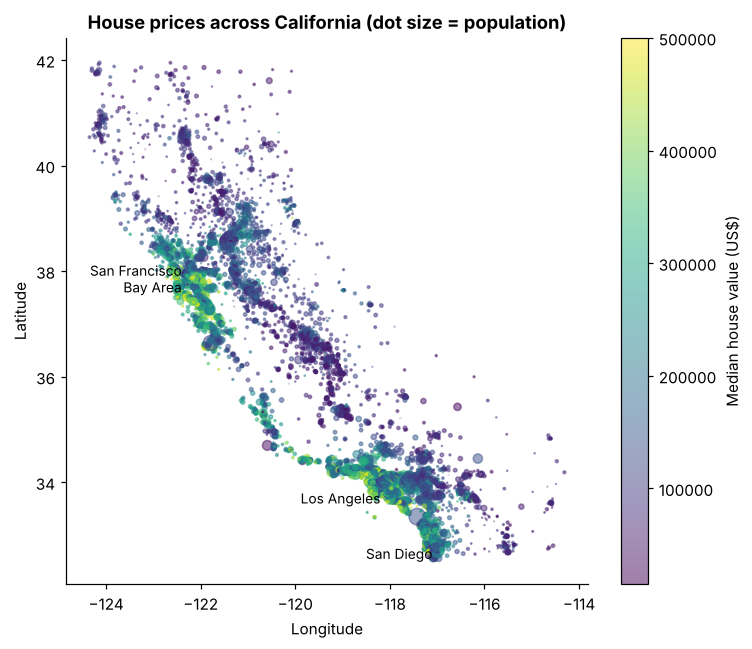

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(df["longitude"], df["latitude"], c=df["median_house_value"], cmap="viridis",
                s=df["population"] / 300, alpha=0.5)
plt.colorbar(sc, label="Median house value (US$)")
ax.text(-122.4, 37.6, "San Francisco\nBay Area", fontsize=9, ha="right")
ax.text(-118.2, 33.6, "Los Angeles", fontsize=9, ha="right")
ax.text(-117.1, 32.55, "San Diego", fontsize=9, ha="right")
ax.set(title="House prices across California (dot size = population)", xlabel="Longitude", ylabel="Latitude")
ax.grid(False)
save(fig, "fig03_price_map")

The most expensive areas are along the **coast**, especially around **San Francisco** and **Los Angeles**. Inland areas are cheaper.

### 5.3 Correlation – which numbers move together with price?

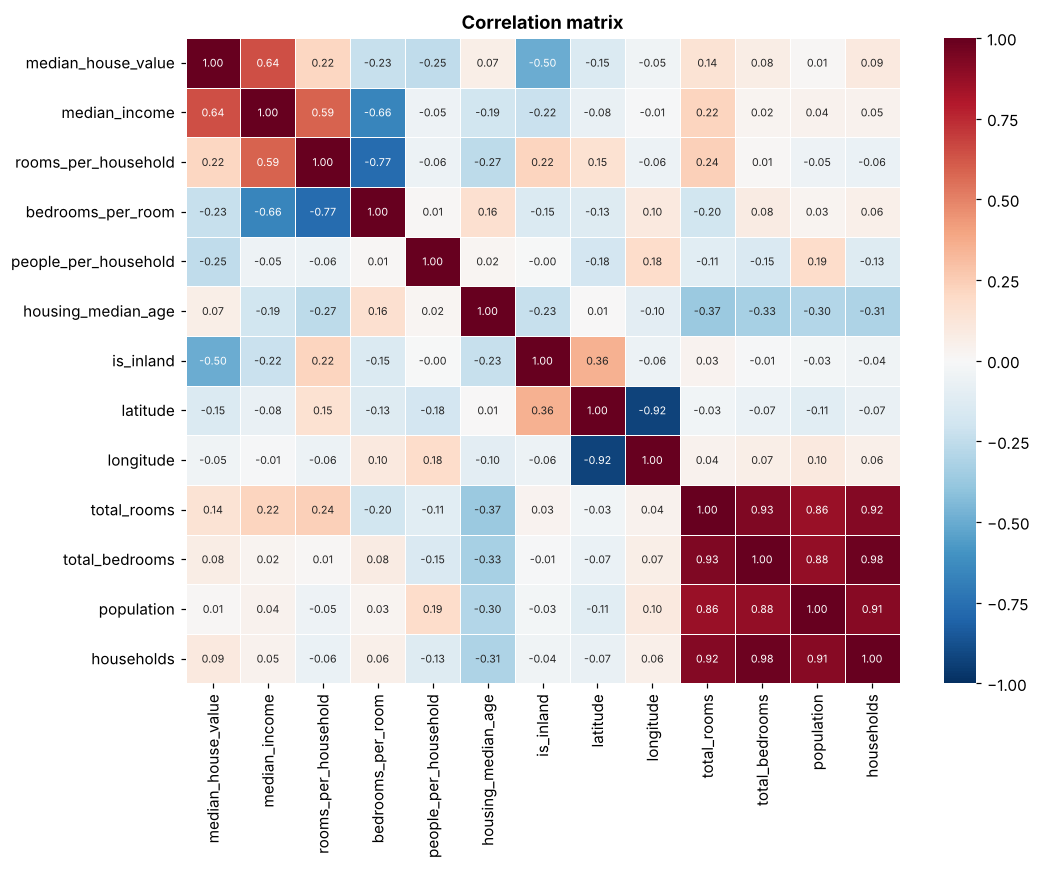

is_inland              -0.499
people_per_household   -0.254
bedrooms_per_room      -0.233
latitude               -0.148
longitude              -0.047
population              0.012
housing_median_age      0.068
total_bedrooms          0.076
households              0.095
total_rooms             0.143
rooms_per_household     0.218
median_income           0.643
Name: median_house_value, dtype: float64


In [ ]:
num_cols = ["median_house_value", "median_income", "rooms_per_household", "bedrooms_per_room",
            "people_per_household", "housing_median_age", "is_inland", "latitude", "longitude",
            "total_rooms", "total_bedrooms", "population", "households"]
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7}, linewidths=0.5, ax=ax)
ax.set_title("Correlation matrix")
save(fig, "fig04_correlation_heatmap")

corr_price = corr["median_house_value"].drop("median_house_value").sort_values()
print(corr_price.round(3))
RESULTS["corr_with_price"] = corr_price.round(3).to_dict()

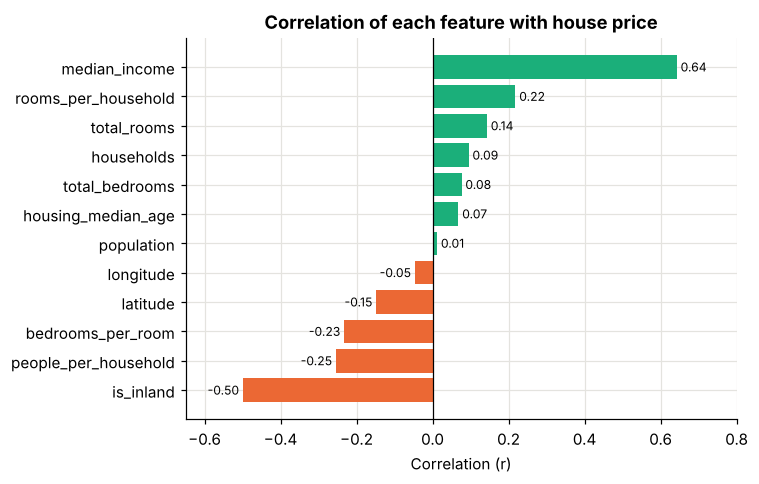

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
colours = [GREEN if v > 0 else ORANGE for v in corr_price]
ax.barh(corr_price.index, corr_price.values, color=colours)
for i, v in enumerate(corr_price.values):
    ax.text(v + (0.01 if v > 0 else -0.01), i, f"{v:.2f}", va="center", ha="left" if v > 0 else "right", fontsize=8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Correlation of each feature with house price", xlabel="Correlation (r)", xlim=(-0.65, 0.8))
save(fig, "fig05_correlation_with_price")

**Key insight:** **median income** has the strongest link to price (r ≈ 0.65). Being **inland** has a strong *negative* link (r ≈ −0.5). The raw totals (rooms, population, households) have almost no link, which shows why we created the per-household features.

### 5.4 Price vs income, location and house size

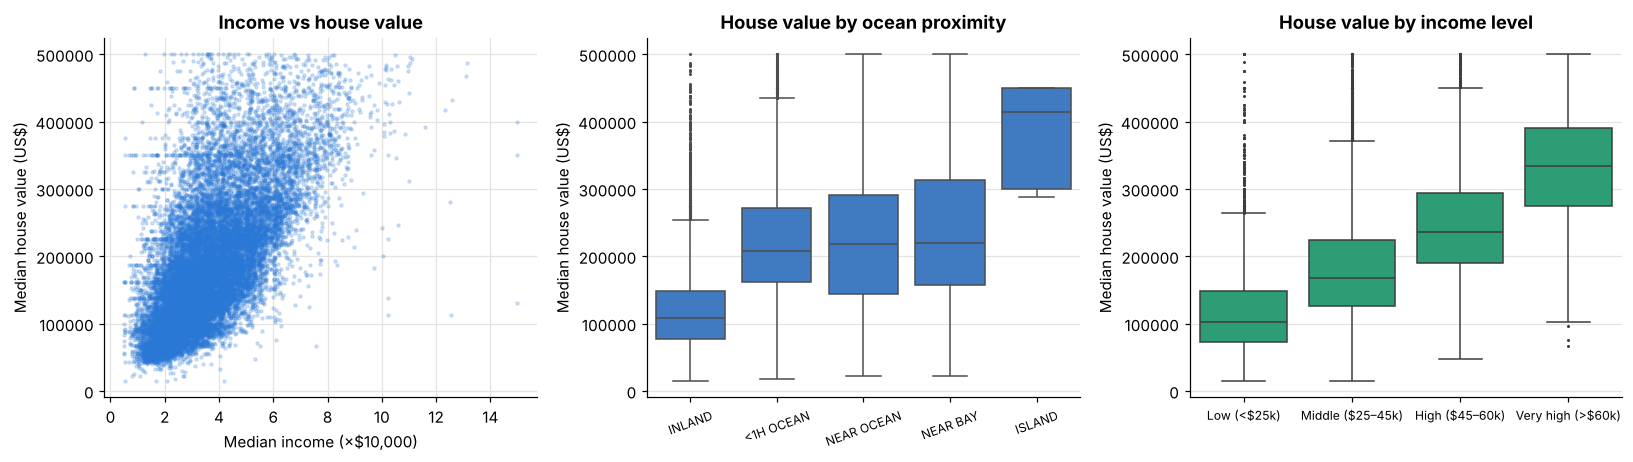

,count,median,mean
ocean_proximity,,,
<1H OCEAN,8604,207650.0,224013.0
INLAND,6524,108300.0,123253.0
ISLAND,5,414700.0,380440.0
NEAR BAY,2096,219850.0,236926.0
NEAR OCEAN,2446,218250.0,227717.0


,count,median,mean
income_level,,,
Low (<$25k),4782,101800.0,119538.0
Middle ($25–45k),9687,168100.0,183600.0
High ($45–60k),3502,236200.0,248834.0
Very high (>$60k),1704,333700.0,331820.0


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

axes[0].scatter(df["median_income"], df["median_house_value"], s=4, alpha=0.2, color=BLUE)
axes[0].set(title="Income vs house value", xlabel="Median income (×$10,000)", ylabel="Median house value (US$)")

order = df.groupby("ocean_proximity", observed=True)["median_house_value"].median().sort_values().index
sns.boxplot(data=df, x="ocean_proximity", y="median_house_value", order=order, color=BLUE,
            fliersize=1, ax=axes[1])
axes[1].set(title="House value by ocean proximity", xlabel="", ylabel="Median house value (US$)")
axes[1].tick_params(axis="x", labelsize=8, rotation=20)

sns.boxplot(data=df, x="income_level", y="median_house_value", color=GREEN, fliersize=1, ax=axes[2])
axes[2].set(title="House value by income level", xlabel="", ylabel="Median house value (US$)")
axes[2].tick_params(axis="x", labelsize=8)
save(fig, "fig06_key_relationships")

by_ocean = df.groupby("ocean_proximity", observed=True)["median_house_value"].agg(["count", "median", "mean"]).round(0)
by_income = df.groupby("income_level", observed=True)["median_house_value"].agg(["count", "median", "mean"]).round(0)
display(by_ocean); display(by_income)
RESULTS["by_ocean"] = by_ocean["median"].to_dict()
RESULTS["by_income"] = {str(k): v for k, v in by_income["median"].to_dict().items()}

**Notable insights**
1. **Income is the biggest driver.** Richer neighbourhoods have much more expensive homes.
2. **Location matters a lot.** Inland homes are far cheaper than coastal ones (Island homes are the most expensive, but there are only 5 of them).
3. **More space per household** (rooms per household) is linked to higher prices, and a **higher share of bedrooms** (smaller living areas) to lower prices.
4. **Crowded homes** (more people per household) are linked to lower prices.

## Step 6 – Build the models

### Why these algorithms?
| Algorithm | Why we use it |
|---|---|
| **Multiple Linear Regression** (mandatory) | Simple and easy to explain. Each coefficient shows how much the price changes when one feature changes. A good baseline. |
| **Decision Tree** | Can find non-linear patterns (e.g. "inland AND low income → cheap") and gives easy if–then rules. |
| **Random Forest** | Combines hundreds of decision trees and averages them. Usually much more accurate and less likely to overfit than one tree. |

### How we test them fairly
* **80% training data** (the model learns from it) and **20% test data** (hidden until the end to check accuracy).
* **5-fold cross-validation** on the training data to check the results are stable.

In [ ]:
# Features (X) and target (y)
FEATURES = ["median_income", "housing_median_age", "rooms_per_household", "bedrooms_per_room",
            "people_per_household", "latitude", "longitude", "population", "households", "ocean_proximity"]
X = pd.get_dummies(df[FEATURES], columns=["ocean_proximity"], prefix="ocean", drop_first=True, dtype=int)
y = df["median_house_value"]
print("Model input columns:", list(X.columns))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")
RESULTS["n_train"], RESULTS["n_test"] = len(X_train), len(X_test)

Model input columns: ['median_income', 'housing_median_age', 'rooms_per_household', 'bedrooms_per_room', 'people_per_household', 'latitude', 'longitude', 'population', 'households', 'ocean_INLAND', 'ocean_ISLAND', 'ocean_NEAR BAY', 'ocean_NEAR OCEAN']
Training rows: 15740 | Test rows: 3935


In [ ]:
def evaluate(name, model):
    # Train the model, test it, and return R², MAE, RMSE and cross-validation R²
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    cv = cross_val_score(model, X_train, y_train, cv=5, scoring="r2")
    return {"Model": name,
            "R2": r2_score(y_test, pred),
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "CV R2 (mean)": cv.mean(), "CV R2 (std)": cv.std()}, pred

results, predictions, models = [], {}, {}

### 6.1 Multiple Linear Regression
The model learns a straight-line formula:

**price = b₀ + b₁ × income + b₂ × house age + … + bₙ × featureₙ**

We **standardise** the features first (put them on the same scale), so we can compare the size of the coefficients fairly.

{'Model': 'Multiple Linear Regression', 'R2': 0.646, 'MAE': 44088.554, 'RMSE': np.float64(59432.184), 'CV R2 (mean)': np.float64(0.642), 'CV R2 (std)': np.float64(0.007)}

Intercept: 192191
latitude               -55715.0
longitude              -54433.0
people_per_household   -20292.0
ocean_INLAND           -15992.0
ocean_NEAR BAY          -3773.0
population              -2453.0
ocean_NEAR OCEAN         -662.0
ocean_ISLAND             2377.0
households               7403.0
rooms_per_household     11608.0
housing_median_age      12462.0
bedrooms_per_room       20482.0
median_income           62012.0
dtype: float64


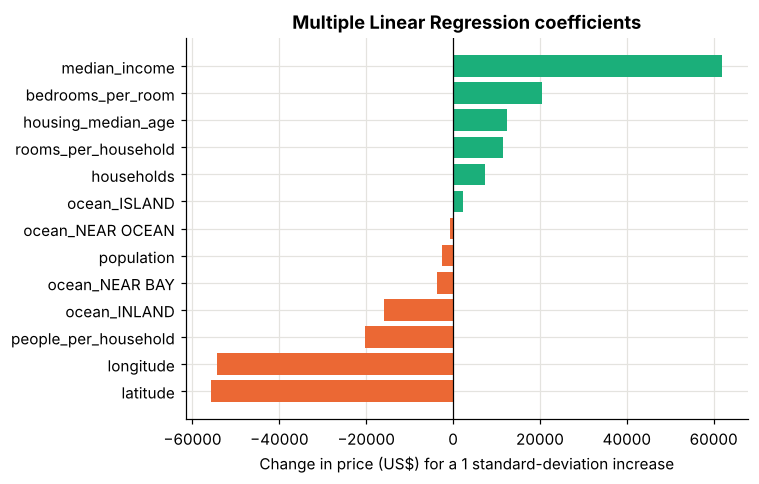

In [ ]:
mlr = make_pipeline(StandardScaler(), LinearRegression())
res, predictions["Multiple Linear Regression"] = evaluate("Multiple Linear Regression", mlr)
results.append(res); models["Multiple Linear Regression"] = mlr
print({k: round(v, 3) if isinstance(v, float) else v for k, v in res.items()})

# Coefficients: how much price changes (US$) when a feature goes up by 1 standard deviation
coefs = pd.Series(mlr[-1].coef_, index=X.columns).sort_values()
print("\nIntercept:", round(mlr[-1].intercept_))
print(coefs.round(0))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(coefs.index, coefs.values, color=[GREEN if v > 0 else ORANGE for v in coefs])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Multiple Linear Regression coefficients",
       xlabel="Change in price (US$) for a 1 standard-deviation increase")
save(fig, "fig07_mlr_coefficients")
RESULTS["mlr_coefs"] = coefs.round(0).to_dict()

**How to read this:** if median income goes up by one standard deviation (about $16,000), the model expects the house value to rise by tens of thousands of dollars, holding other things equal. Latitude and longitude have large coefficients because together they describe location (north/south and east/west).

### 6.2 Decision Tree
A decision tree asks yes/no questions (for example "Is income below $50k?") and splits the data step by step. If the tree is too deep it **memorises** the training data (overfitting), so we test different depths and keep the best one.

In [ ]:
grid = GridSearchCV(DecisionTreeRegressor(random_state=RANDOM_STATE),
                    {"max_depth": [6, 8, 10, 12, 15, 20], "min_samples_leaf": [10, 20, 40]},
                    cv=5, scoring="r2")
grid.fit(X_train, y_train)
print("Best settings:", grid.best_params_)

tree = DecisionTreeRegressor(random_state=RANDOM_STATE, **grid.best_params_)
res, predictions["Decision Tree"] = evaluate("Decision Tree", tree)
results.append(res); models["Decision Tree"] = tree
print({k: round(v, 3) if isinstance(v, float) else v for k, v in res.items()})
RESULTS["tree_params"] = grid.best_params_

Best settings: {'max_depth': 15, 'min_samples_leaf': 20}


{'Model': 'Decision Tree', 'R2': 0.713, 'MAE': 36700.289, 'RMSE': np.float64(53498.317), 'CV R2 (mean)': np.float64(0.707), 'CV R2 (std)': np.float64(0.011)}


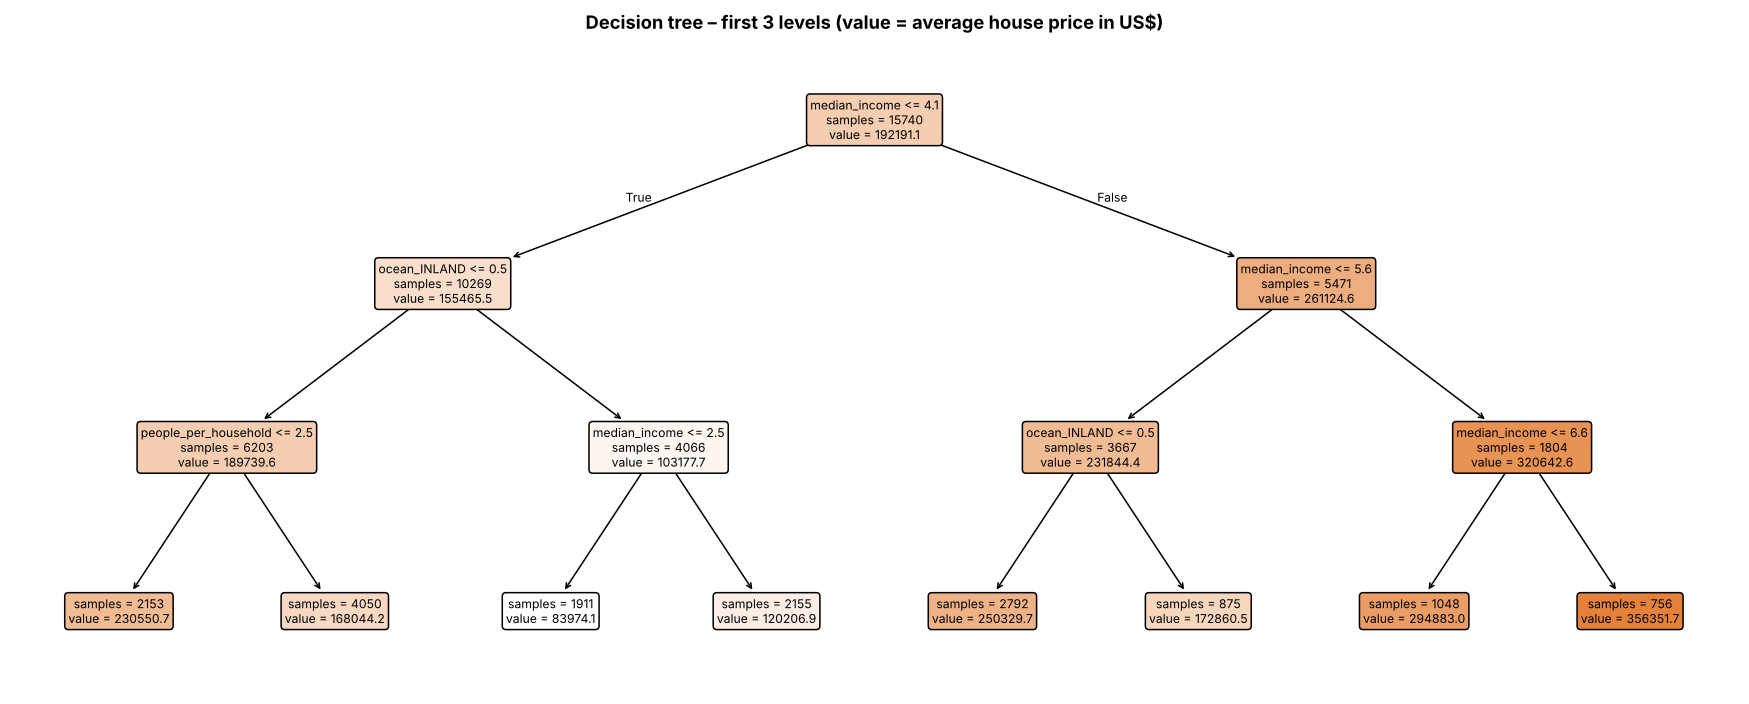

In [ ]:
# Draw a small 3-level tree so the rules are easy to read
small_tree = DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(16, 6.5))
plot_tree(small_tree, feature_names=X.columns, filled=True, rounded=True, impurity=False,
          precision=1, fontsize=8, ax=ax)
ax.set_title("Decision tree – first 3 levels (value = average house price in US$)")
save(fig, "fig08_decision_tree")

### 6.3 Random Forest
A random forest builds **200 different decision trees**, each on a random sample of the data and features, and **averages** their predictions. Averaging many trees cancels out their individual mistakes.

In [ ]:
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, max_features=0.5,
                           random_state=RANDOM_STATE, n_jobs=-1)
res, predictions["Random Forest"] = evaluate("Random Forest", rf)
results.append(res); models["Random Forest"] = rf
print({k: round(v, 3) if isinstance(v, float) else v for k, v in res.items()})

{'Model': 'Random Forest', 'R2': 0.794, 'MAE': 30268.891, 'RMSE': np.float64(45328.839), 'CV R2 (mean)': np.float64(0.791), 'CV R2 (std)': np.float64(0.005)}


## Step 7 – Evaluate and compare the models

| Metric | Meaning | Better when |
|---|---|---|
| **R²** | % of the variation in prices the model explains (1 = perfect) | Higher |
| **MAE** | Average error in US$ | Lower |
| **RMSE** | Like MAE but punishes big mistakes more | Lower |

In [ ]:
# Baseline: always guess the average price (any useful model must beat this)
base = np.full(len(y_test), y_train.mean())
results.append({"Model": "Baseline (always guess the average)", "R2": r2_score(y_test, base),
                "MAE": mean_absolute_error(y_test, base), "RMSE": np.sqrt(mean_squared_error(y_test, base))})

comparison = pd.DataFrame(results).set_index("Model")
comparison.to_csv("results/model_comparison.csv")
display(comparison.style.format({"R2": "{:.3f}", "MAE": "${:,.0f}", "RMSE": "${:,.0f}",
                                 "CV R2 (mean)": "{:.3f}", "CV R2 (std)": "{:.3f}"}, na_rep="-"))
RESULTS["comparison"] = comparison.round(3).reset_index().to_dict(orient="records")

,R2,MAE,RMSE,CV R2 (mean),CV R2 (std)
Model,,,,,
Multiple Linear Regression,0.646,"$44,089","$59,432",0.642,0.007
Decision Tree,0.713,"$36,700","$53,498",0.707,0.011
Random Forest,0.794,"$30,269","$45,329",0.791,0.005
Baseline (always guess the average),-0.000,"$80,135","$99,865",-,-


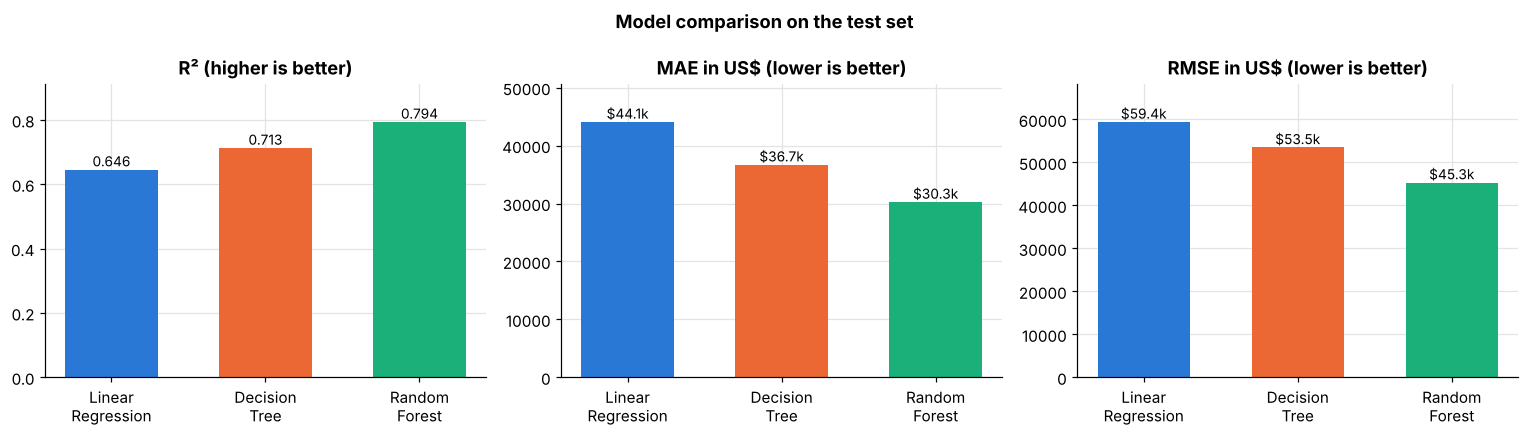

In [ ]:
names = list(MODEL_COLOURS)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric, title in zip(axes, ["R2", "MAE", "RMSE"],
                             ["R² (higher is better)", "MAE in US$ (lower is better)", "RMSE in US$ (lower is better)"]):
    vals = comparison.loc[names, metric]
    bars = ax.bar(range(3), vals, color=[MODEL_COLOURS[n] for n in names], width=0.6)
    ax.bar_label(bars, labels=[f"{v:.3f}" if metric == "R2" else f"${v/1000:,.1f}k" for v in vals], fontsize=9)
    ax.set_xticks(range(3), ["Linear\nRegression", "Decision\nTree", "Random\nForest"])
    ax.set_title(title); ax.margins(y=0.15)
fig.suptitle("Model comparison on the test set", fontweight="bold")
save(fig, "fig09_model_comparison")

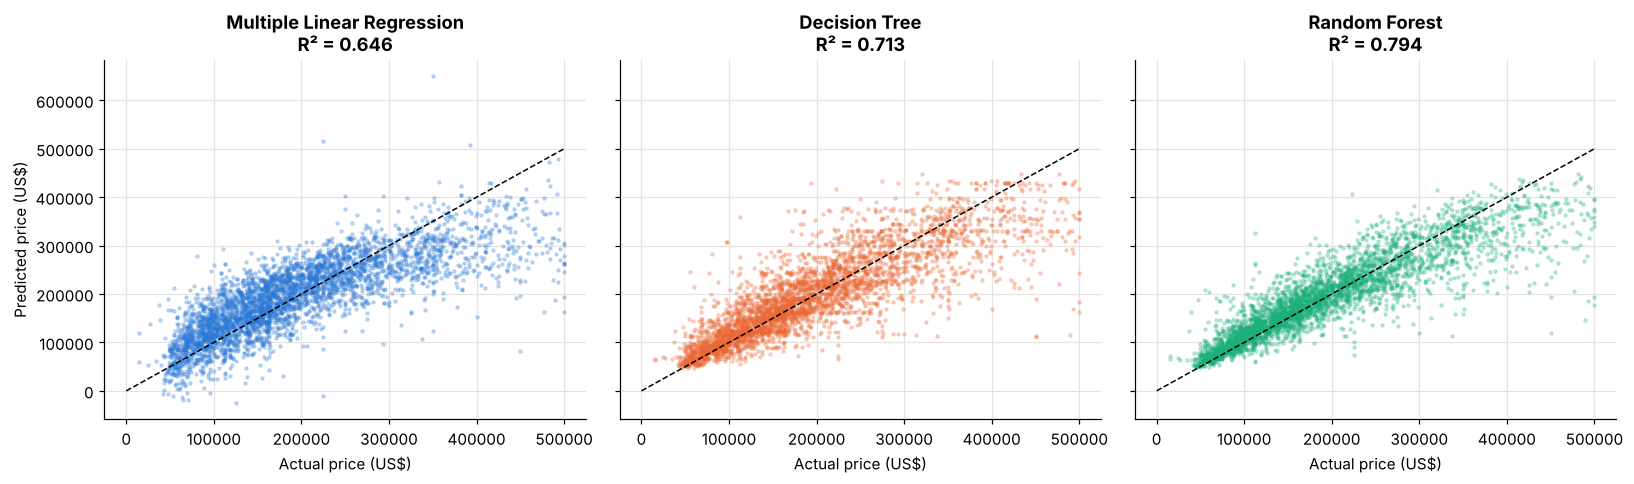

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
for ax, name in zip(axes, names):
    p = predictions[name]
    ax.scatter(y_test, p, s=4, alpha=0.25, color=MODEL_COLOURS[name])
    ax.plot([0, 500000], [0, 500000], "k--", linewidth=1)
    ax.set(title=f"{name}\nR² = {r2_score(y_test, p):.3f}", xlabel="Actual price (US$)")
axes[0].set_ylabel("Predicted price (US$)")
save(fig, "fig10_predicted_vs_actual")

Points close to the dashed line are good predictions. The Random Forest points are much closer to the line than the Linear Regression points.

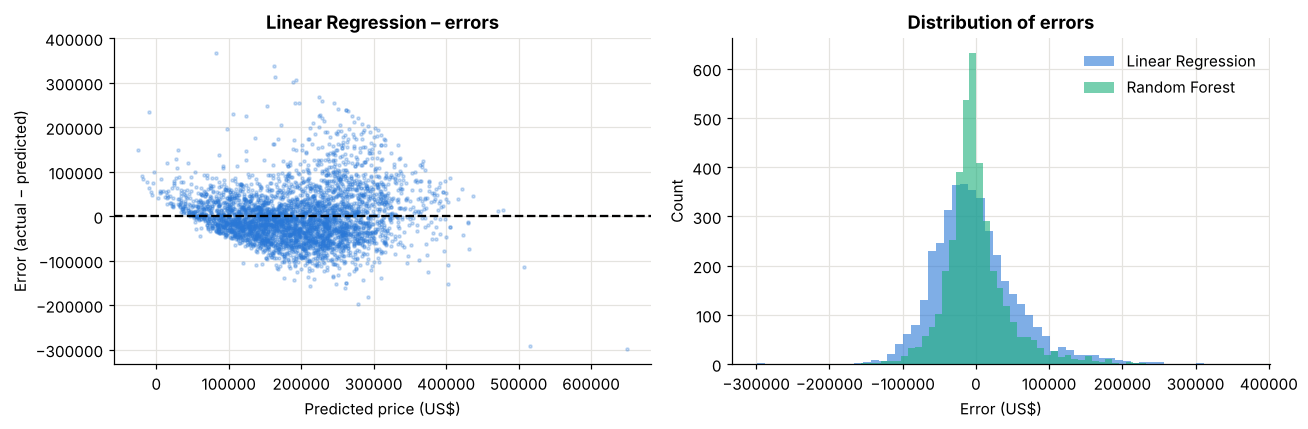

In [ ]:
# Errors (residuals) of the linear model: shows where a straight line is not enough
res_mlr = y_test - predictions["Multiple Linear Regression"]
res_rf = y_test - predictions["Random Forest"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(predictions["Multiple Linear Regression"], res_mlr, s=4, alpha=0.25, color=BLUE)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set(title="Linear Regression – errors", xlabel="Predicted price (US$)", ylabel="Error (actual − predicted)")
axes[1].hist(res_mlr, bins=60, alpha=0.6, color=BLUE, label="Linear Regression")
axes[1].hist(res_rf, bins=60, alpha=0.6, color=GREEN, label="Random Forest")
axes[1].set(title="Distribution of errors", xlabel="Error (US$)", ylabel="Count")
axes[1].legend(frameon=False)
save(fig, "fig11_errors")

The linear model's errors form a curved pattern: it under-predicts cheap and very expensive areas. This means **the relationship is not a straight line**, which is why the tree-based models do better. The Random Forest errors are much narrower around zero.

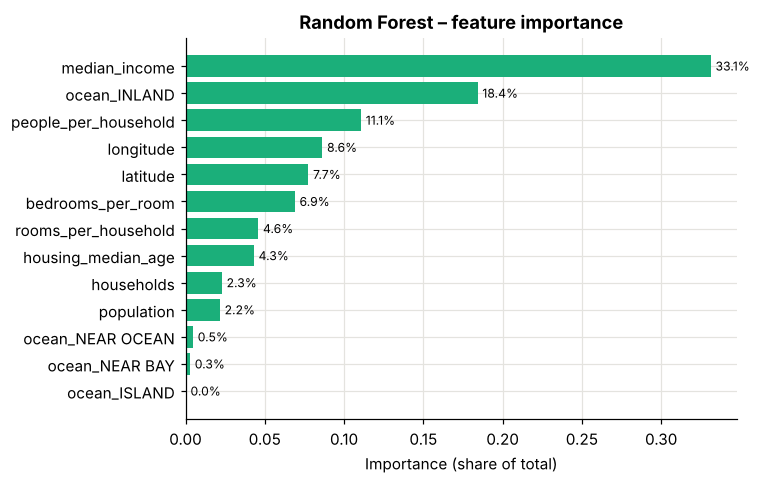

median_income           0.331
ocean_INLAND            0.184
people_per_household    0.111
longitude               0.086
latitude                0.077
bedrooms_per_room       0.069
rooms_per_household     0.046
housing_median_age      0.043
households              0.023
population              0.022
ocean_NEAR OCEAN        0.005
ocean_NEAR BAY          0.003
ocean_ISLAND            0.000
dtype: float64


In [ ]:
# Which features matter most to the Random Forest?
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importance.to_csv("results/rf_feature_importance.csv")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(importance.index, importance.values, color=GREEN)
for i, v in enumerate(importance.values):
    ax.text(v + 0.003, i, f"{v:.1%}", va="center", fontsize=8)
ax.set(title="Random Forest – feature importance", xlabel="Importance (share of total)")
save(fig, "fig12_feature_importance")
print(importance.sort_values(ascending=False).round(3))
RESULTS["importance"] = importance.sort_values(ascending=False).round(3).to_dict()

## Step 8 – K-Means clustering: grouping neighbourhoods
Now we use an **unsupervised** method. K-Means puts similar neighbourhoods into groups (clusters) **without looking at the price**. Then we check whether the groups have different prices.

**Features used:** income, house age, rooms per household, people per household, bedrooms per room and the inland flag (all standardised). Price and map coordinates are **not** used, so we can check afterwards whether the groups differ in price and location.

**How many groups?** We use the **elbow method** and the **silhouette score** (how well separated the groups are).

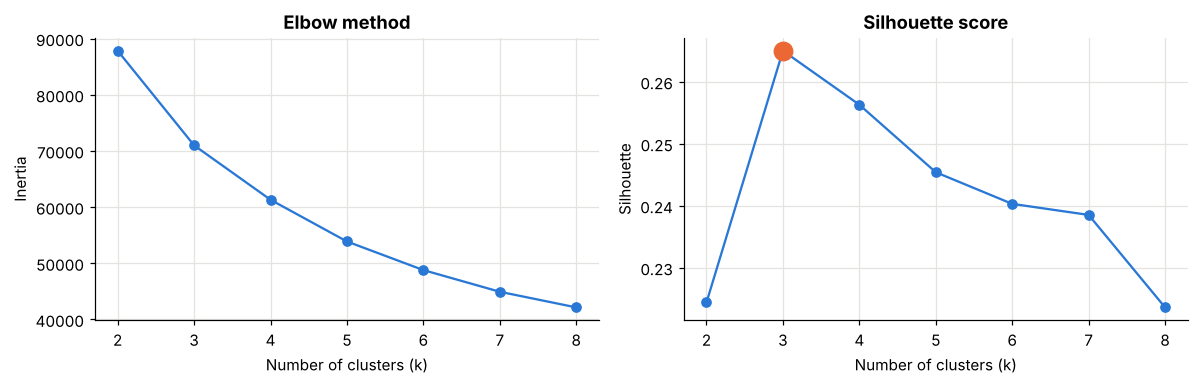

Silhouette: {2: np.float64(0.224), 3: np.float64(0.265), 4: np.float64(0.256), 5: np.float64(0.245), 6: np.float64(0.24), 7: np.float64(0.239), 8: np.float64(0.224)} → chosen k = 3


In [ ]:
CLUSTER_FEATURES = ["median_income", "housing_median_age", "rooms_per_household",
                    "people_per_household", "bedrooms_per_room", "is_inland"]
Xc = StandardScaler().fit_transform(df[CLUSTER_FEATURES])

ks = list(range(2, 9))
inertia, silhouette = [], []
sample = np.random.RandomState(RANDOM_STATE).choice(len(Xc), 5000, replace=False)  # sample for speed
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xc)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(Xc[sample], km.labels_[sample]))
best_k = ks[int(np.argmax(silhouette[1:5])) + 1]   # best among k = 3–6 (useful number of groups)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(ks, inertia, "o-", color=BLUE); axes[0].set(title="Elbow method", xlabel="Number of clusters (k)", ylabel="Inertia")
axes[1].plot(ks, silhouette, "o-", color=BLUE)
axes[1].plot(best_k, silhouette[ks.index(best_k)], "o", color=ORANGE, markersize=12)
axes[1].set(title="Silhouette score", xlabel="Number of clusters (k)", ylabel="Silhouette")
save(fig, "fig13_choose_k")
print("Silhouette:", dict(zip(ks, np.round(silhouette, 3))), "→ chosen k =", best_k)
RESULTS["silhouette"] = dict(zip(map(str, ks), np.round(silhouette, 3).tolist())); RESULTS["k"] = best_k

In [ ]:
kmeans = KMeans(n_clusters=best_k, n_init=20, random_state=RANDOM_STATE).fit(Xc)
df["cluster"] = kmeans.labels_
# Number the clusters from most to least expensive so they are easy to talk about
order = df.groupby("cluster")["median_house_value"].median().sort_values(ascending=False).index
df["cluster"] = df["cluster"].map({old: new + 1 for new, old in enumerate(order)})

profile = df.groupby("cluster")[CLUSTER_FEATURES[:-1] + ["median_house_value"]].median().round(2)
profile.insert(0, "neighbourhoods", df["cluster"].value_counts().sort_index())
profile["% inland"] = (df.groupby("cluster")["is_inland"].mean() * 100).round(1)
profile.to_csv("results/cluster_profiles.csv")
display(profile)
RESULTS["clusters"] = profile.reset_index().to_dict(orient="records")

,neighbourhoods,median_income,housing_median_age,rooms_per_household,people_per_household,bedrooms_per_room,median_house_value,% inland
cluster,,,,,,,,
1,6425,5.05,27.0,5.94,2.85,0.17,251400.0,4.3
2,7316,2.78,34.0,4.25,2.82,0.25,170700.0,4.3
3,5934,2.99,22.0,5.49,2.84,0.20,107100.0,100.0


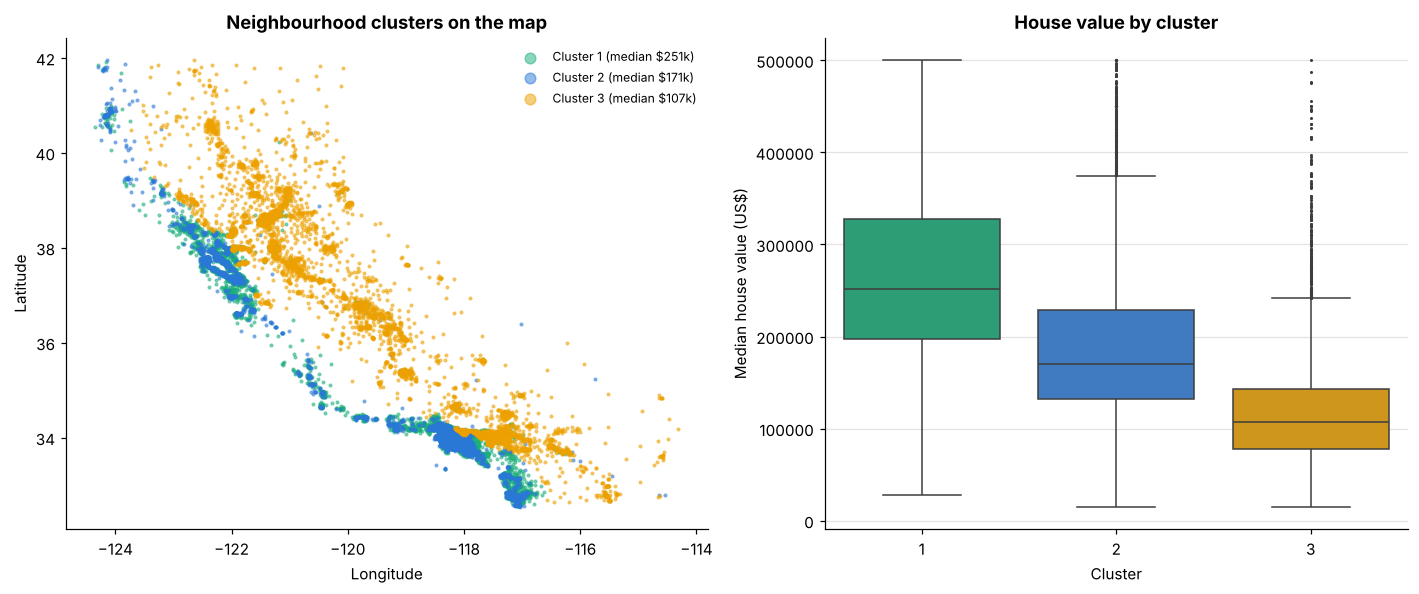

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
palette = [GREEN, BLUE, YELLOW, ORANGE, PINK, PURPLE]
for c in sorted(df["cluster"].unique()):
    m = df["cluster"] == c
    axes[0].scatter(df.loc[m, "longitude"], df.loc[m, "latitude"], s=3, alpha=0.5, color=palette[c - 1],
                    label=f"Cluster {c} (median ${profile.loc[c, 'median_house_value']/1000:,.0f}k)")
axes[0].set(title="Neighbourhood clusters on the map", xlabel="Longitude", ylabel="Latitude")
axes[0].legend(frameon=False, markerscale=4, fontsize=8); axes[0].grid(False)

sns.boxplot(data=df, x="cluster", y="median_house_value", palette=palette[:best_k], fliersize=1, ax=axes[1])
axes[1].set(title="House value by cluster", xlabel="Cluster", ylabel="Median house value (US$)")
save(fig, "fig14_clusters")

The clusters were found **without using price**, yet they have very different prices. Each cluster is a different "type" of neighbourhood (for example rich coastal areas, older city areas, cheaper inland areas). These can guide different housing policies.

## Step 9 – Summary of findings

In [ ]:
with open("results/results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=str)

best = comparison.drop("Baseline (always guess the average)")["R2"].idxmax()
print(f"Best model: {best}")
print(f"  R² = {comparison.loc[best, 'R2']:.3f}, average error (MAE) = ${comparison.loc[best, 'MAE']:,.0f}")
print("Top 3 factors (Random Forest):", ", ".join(importance.sort_values(ascending=False).index[:3]))
print(f"Neighbourhood groups found by K-Means: {best_k}")

Best model: Random Forest
  R² = 0.794, average error (MAE) = $30,269
Top 3 factors (Random Forest): median_income, ocean_INLAND, people_per_household
Neighbourhood groups found by K-Means: 3


### Conclusions
1. **Income and location are the main drivers of house prices.** Median income has the strongest link with price, and inland areas are much cheaper than coastal ones.
2. **Random Forest is the best model.** It explains about 80% of the variation in prices, much better than Linear Regression (about 64%), because the relationships are not straight lines.
3. **Linear Regression is still useful** because it is simple and shows the direction of each effect clearly.
4. **K-Means found distinct neighbourhood types** with very different prices, without being given the price.

The written report explains these results in detail and gives recommendations.